# BharatMarket AI
## Indian Stock Market Analysis and Forecasting System

**Course:** CS3216 – Time Series Analysis and Forecasting

### Project Objectives
1. Analyse NIFTY 50 and BANK NIFTY.
2. Analyse 8 major NSE-listed companies.
3. Study historical stock market trends.
4. Apply statistical forecasting models.
5. Develop machine learning forecasting models.
6. Evaluate forecasting accuracy.
7. Develop a historical trading signal engine.
8. Backtest trading strategies.

### Historical Data
- Period: November 2021 – November 2026
- Frequency: Daily
- Instruments: 10
- Data source: Historical CSV datasets

In [1]:
# ============================================
# BHARATMARKET AI
# CELL 1: IMPORT LIBRARIES
# ============================================

import os
import shutil
import zipfile
import warnings

from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from IPython.display import display

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["axes.titlesize"] = 15

print("==========================================")
print("          BHARATMARKET AI")
print(" Indian Stock Market Analysis & Forecasting")
print("==========================================")

print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

print("\nLibraries imported successfully!")

          BHARATMARKET AI
 Indian Stock Market Analysis & Forecasting
Pandas version: 3.1.1
NumPy version: 2.5.5

Libraries imported successfully!


In [2]:
# ============================================
# CELL 2: PROJECT CONFIGURATION
# ============================================

PROJECT_DIR = Path(
    r"C:\Users\adity\Downloads\Historical data\BharatMarket_AI"
)

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"

OUTPUT_DIR = PROJECT_DIR / "outputs"

CHART_DIR = OUTPUT_DIR / "charts"
REPORT_DIR = OUTPUT_DIR / "reports"
MODEL_DIR = OUTPUT_DIR / "models"

# Create all required directories
directories = [
    RAW_DATA_DIR,
    PROCESSED_DATA_DIR,
    CHART_DIR,
    REPORT_DIR,
    MODEL_DIR
]

for folder in directories:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Raw data directory:", RAW_DATA_DIR)

print("\nProject directories created successfully!")

Project directory: C:\Users\adity\Downloads\Historical data\BharatMarket_AI
Raw data directory: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\data\raw

Project directories created successfully!


In [3]:
# ============================================
# CELL 3: INSTRUMENT CONFIGURATION
# ============================================

INSTRUMENTS = {
    "NIFTY50": "NIFTY 50",
    "BANKNIFTY": "BANK NIFTY",
    "RELIANCE": "Reliance Industries",
    "TCS": "Tata Consultancy Services",
    "HDFCBANK": "HDFC Bank",
    "INFY": "Infosys",
    "ICICIBANK": "ICICI Bank",
    "SBIN": "State Bank of India",
    "ITC": "ITC Limited",
    "LT": "Larsen & Toubro"
}

print("Total instruments:", len(INSTRUMENTS))

for symbol, company in INSTRUMENTS.items():
    print(f"{symbol}: {company}")

Total instruments: 10
NIFTY50: NIFTY 50
BANKNIFTY: BANK NIFTY
RELIANCE: Reliance Industries
TCS: Tata Consultancy Services
HDFCBANK: HDFC Bank
INFY: Infosys
ICICIBANK: ICICI Bank
SBIN: State Bank of India
ITC: ITC Limited
LT: Larsen & Toubro


In [4]:
# ============================================
# CELL 4: LOCATE HISTORICAL DATA FILES
# ============================================

EXPECTED_FILES = [
    f"{symbol}.csv"
    for symbol in INSTRUMENTS.keys()
]

SEARCH_ROOTS = [
    PROJECT_DIR,
    PROJECT_DIR.parent
]

found_files = {}

# First search extracted folders
for filename in EXPECTED_FILES:

    for root in SEARCH_ROOTS:

        matches = [
            p for p in root.rglob("*")
            if p.is_file() and p.name.lower() == filename.lower()
        ]

        if matches:
            found_files[filename] = matches[0]
            break

# Search ZIP archives if any files are missing
missing_files = [
    f for f in EXPECTED_FILES
    if f not in found_files
]

zip_files = []

for root in SEARCH_ROOTS:
    zip_files.extend(root.glob("*.zip"))

for zip_path in zip_files:

    if not missing_files:
        break

    print("Checking ZIP:", zip_path.name)

    try:
        with zipfile.ZipFile(zip_path, "r") as archive:

            for member in archive.namelist():

                basename = Path(member).name.lower()

                for filename in missing_files:

                    if basename == filename.lower():

                        destination = RAW_DATA_DIR / filename

                        with archive.open(member) as source:
                            with open(destination, "wb") as target:
                                shutil.copyfileobj(source, target)

                        found_files[filename] = destination

            missing_files = [
                f for f in EXPECTED_FILES
                if f not in found_files
            ]

    except zipfile.BadZipFile:
        print("Invalid ZIP file:", zip_path.name)

# Copy discovered files into the standard raw data folder
for filename, source in found_files.items():

    destination = RAW_DATA_DIR / filename

    if source.resolve() != destination.resolve():
        shutil.copy2(source, destination)

# Final file check
print("\n========== DATA FILE STATUS ==========")

for filename in EXPECTED_FILES:

    if (RAW_DATA_DIR / filename).exists():
        print("FOUND:", filename)
    else:
        print("MISSING:", filename)

print("\nTotal files found:", len([
    f for f in EXPECTED_FILES
    if (RAW_DATA_DIR / f).exists()
]), "/", len(EXPECTED_FILES))


========== DATA FILE STATUS ==========
FOUND: NIFTY50.csv
FOUND: BANKNIFTY.csv
FOUND: RELIANCE.csv
FOUND: TCS.csv
FOUND: HDFCBANK.csv
FOUND: INFY.csv
FOUND: ICICIBANK.csv
FOUND: SBIN.csv
FOUND: ITC.csv
FOUND: LT.csv

Total files found: 10 / 10


In [5]:
# ============================================
# CELL 5: LOAD HISTORICAL MARKET DATA
# ============================================

market_data = {}

for symbol, company in INSTRUMENTS.items():

    file_path = RAW_DATA_DIR / f"{symbol}.csv"

    if not file_path.exists():
        print(f"WARNING: {symbol}.csv not found")
        continue

    try:

        df = pd.read_csv(file_path)

        # Standardize column names
        df.columns = [
            str(col).strip().lower().replace(" ", "_")
            for col in df.columns
        ]

        # Handle common column naming variations
        df = df.rename(columns={
            "datetime": "date",
            "timestamp": "date",
            "adj._close": "adj_close",
            "adjusted_close": "adj_close"
        })

        if "date" not in df.columns:
            print(f"ERROR: Date column missing in {symbol}")
            continue

        # Convert dates
        df["date"] = pd.to_datetime(
            df["date"],
            errors="coerce"
        )

        # Convert numerical columns
        numerical_columns = [
            "open",
            "high",
            "low",
            "close",
            "adj_close",
            "volume"
        ]

        for col in numerical_columns:

            if col in df.columns:
                df[col] = pd.to_numeric(
                    df[col],
                    errors="coerce"
                )

        # Sort chronologically
        df = df.sort_values(
            "date"
        ).reset_index(drop=True)

        market_data[symbol] = df

        print(
            f"{symbol}: {len(df):,} records loaded successfully"
        )

    except Exception as error:

        print(f"ERROR loading {symbol}: {error}")

print("\n================================")
print("TOTAL DATASETS:", len(market_data))
print("================================")

if len(market_data) == 0:
    raise RuntimeError(
        "No datasets loaded. Check the CSV file locations in data/raw."
    )

NIFTY50: 1,236 records loaded successfully
BANKNIFTY: 1,235 records loaded successfully
RELIANCE: 1,237 records loaded successfully
TCS: 1,237 records loaded successfully
HDFCBANK: 1,237 records loaded successfully
INFY: 1,237 records loaded successfully
ICICIBANK: 1,237 records loaded successfully
SBIN: 1,237 records loaded successfully
ITC: 1,237 records loaded successfully
LT: 1,237 records loaded successfully

TOTAL DATASETS: 10


In [6]:
# ============================================
# CELL 6: DATASET STRUCTURE VALIDATION
# ============================================

required_columns = [
    "date",
    "open",
    "high",
    "low",
    "close",
    "volume"
]

validation_results = []

for symbol, df in market_data.items():

    missing_columns = [
        col for col in required_columns
        if col not in df.columns
    ]

    validation_results.append({

        "Symbol": symbol,

        "Company": INSTRUMENTS[symbol],

        "Total Rows": len(df),

        "Start Date": df["date"].min(),

        "End Date": df["date"].max(),

        "Missing Values": int(
            df.isna().sum().sum()
        ),

        "Duplicate Dates": int(
            df["date"].duplicated().sum()
        ),

        "Missing Columns": ", ".join(
            missing_columns
        ) if missing_columns else "None"

    })

validation_df = pd.DataFrame(validation_results)

display(validation_df)

,Symbol,Company,Total Rows,Start Date,End Date,Missing Values,Duplicate Dates,Missing Columns
0,NIFTY50,NIFTY 50,1236,2021-11-23,2026-11-23,0,0,None
1,BANKNIFTY,BANK NIFTY,1235,2021-11-23,2026-11-23,0,0,None
2,RELIANCE,Reliance Industries,1237,2021-11-23,2026-11-23,0,0,None
3,TCS,Tata Consultancy Services,1237,2021-11-23,2026-11-23,0,0,None
4,HDFCBANK,HDFC Bank,1237,2021-11-23,2026-11-23,0,0,None
5,INFY,Infosys,1237,2021-11-23,2026-11-23,0,0,None
6,ICICIBANK,ICICI Bank,1237,2021-11-23,2026-11-23,0,0,None
7,SBIN,State Bank of India,1237,2021-11-23,2026-11-23,0,0,None
8,ITC,ITC Limited,1237,2021-11-23,2026-11-23,0,0,None
9,LT,Larsen & Toubro,1237,2021-11-23,2026-11-23,0,0,None


In [7]:
# ============================================
# CELL 7: PRICE AND VOLUME VALIDATION
# ============================================

quality_results = []

for symbol, df in market_data.items():

    required = [
        "open", "high", "low", "close", "volume"
    ]

    if not all(col in df.columns for col in required):
        continue

    invalid_ohlc = (
        (df["high"] < df["low"]) |
        (df["high"] < df["open"]) |
        (df["high"] < df["close"]) |
        (df["low"] > df["open"]) |
        (df["low"] > df["close"])
    )

    invalid_prices = (
        df[["open", "high", "low", "close"]]
        .le(0)
        .any(axis=1)
    )

    negative_volume = df["volume"] < 0

    quality_results.append({

        "Symbol": symbol,

        "Invalid OHLC Rows": int(invalid_ohlc.sum()),

        "Invalid Price Rows": int(invalid_prices.sum()),

        "Negative Volume Rows": int(negative_volume.sum()),

        "Invalid Dates": int(df["date"].isna().sum())

    })

quality_df = pd.DataFrame(quality_results)

display(quality_df)

,Symbol,Invalid OHLC Rows,Invalid Price Rows,Negative Volume Rows,Invalid Dates
0,NIFTY50,0,0,0,0
1,BANKNIFTY,0,0,0,0
2,RELIANCE,0,0,0,0
3,TCS,0,0,0,0
4,HDFCBANK,0,0,0,0
5,INFY,0,0,0,0
6,ICICIBANK,0,0,0,0
7,SBIN,0,0,0,0
8,ITC,0,0,0,0
9,LT,0,0,0,0


In [8]:
# ============================================
# CELL 8: NIFTY 50 DATA PREVIEW
# ============================================

if "NIFTY50" in market_data:

    nifty = market_data["NIFTY50"]

    print("NIFTY 50 - First 10 Records")

    display(nifty.head(10))

    print("\nNIFTY 50 - Last 10 Records")

    display(nifty.tail(10))

else:

    print("NIFTY 50 dataset is unavailable.")

NIFTY 50 - First 10 Records


,date,adj_close,close,high,low,open,volume
0,2021-11-23,17503.349609,17503.349609,17553.699219,17216.099609,17281.750000,308800
1,2021-11-24,17415.050781,17415.050781,17600.599609,17354.000000,17550.050781,298100
2,2021-11-25,17536.250000,17536.250000,17564.349609,17351.699219,17417.300781,255900
3,2021-11-26,17026.449219,17026.449219,17355.400391,16985.699219,17338.750000,356300
4,2021-11-29,17053.949219,17053.949219,17160.699219,16782.400391,17055.800781,348900
5,2021-11-30,16983.199219,16983.199219,17324.650391,16931.400391,17051.150391,498000
6,2021-12-01,17166.900391,17166.900391,17213.050781,17064.250000,17104.400391,295500
7,2021-12-02,17401.650391,17401.650391,17420.349609,17149.300781,17183.199219,279900
8,2021-12-03,17196.699219,17196.699219,17489.800781,17180.800781,17424.900391,292500
9,2021-12-06,16912.250000,16912.250000,17216.750000,16891.699219,17209.050781,231700



NIFTY 50 - Last 10 Records


,date,adj_close,close,high,low,open,volume
1226,2026-11-09,25044.650391,25044.650391,25084.050781,24838.750000,25076.400391,406200
1227,2026-11-11,25255.050781,25255.050781,25424.349609,25095.349609,25337.800781,458000
1228,2026-11-12,25299.349609,25299.349609,25384.800781,25142.949219,25213.500000,349200
1229,2026-11-13,25144.300781,25144.300781,25246.349609,25054.400391,25209.849609,239600
1230,2026-11-16,25291.099609,25291.099609,25337.599609,25172.099609,25206.150391,352900
1231,2026-11-17,25387.400391,25387.400391,25501.349609,25267.300781,25277.300781,342500
1232,2026-11-18,25227.949219,25227.949219,25390.800781,25141.800781,25323.150391,300000
1233,2026-11-19,25514.300781,25514.300781,25514.300781,25104.800781,25186.800781,328800
1234,2026-11-20,25800.599609,25800.599609,25808.800781,25345.199219,25368.000000,428300
1235,2026-11-23,25349.650391,25349.650391,25992.599609,25343.849609,25929.150391,519100


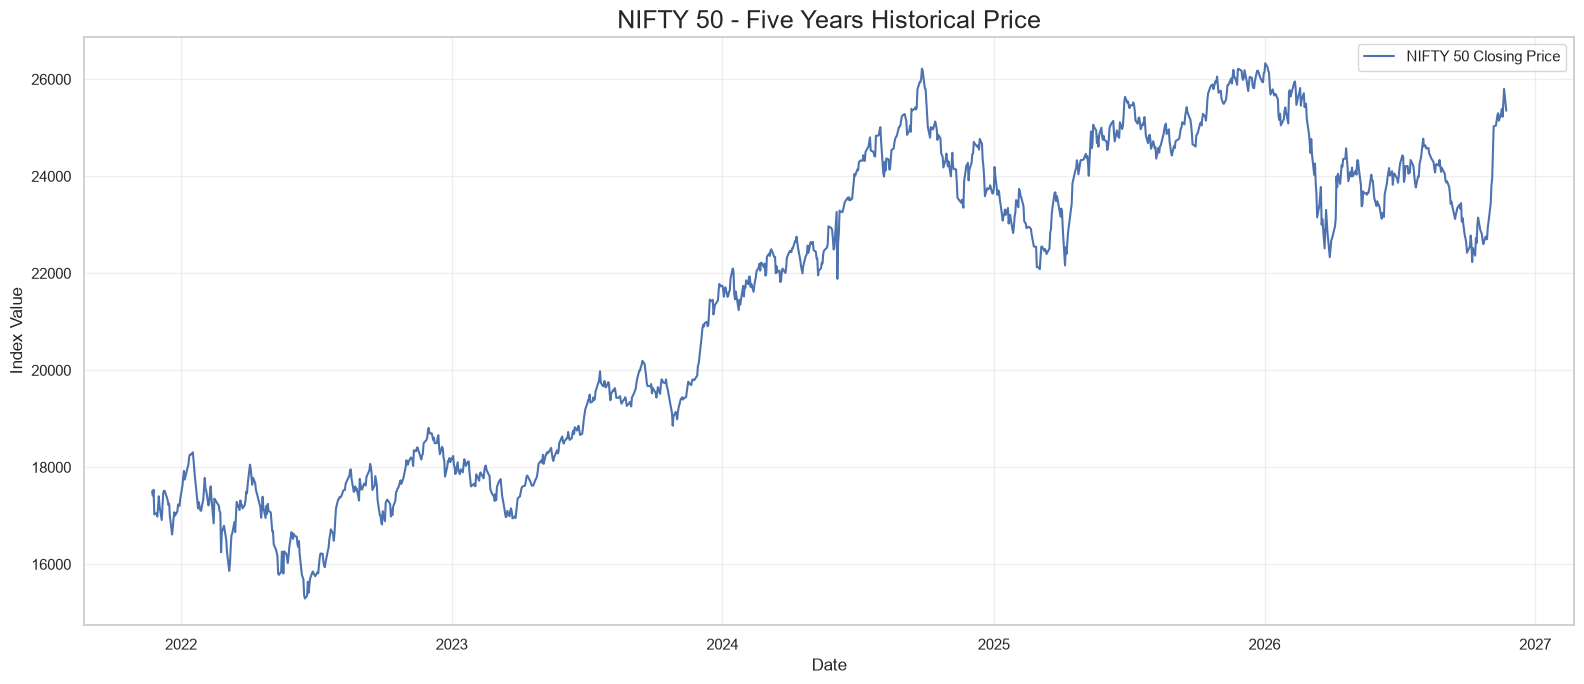

In [9]:
# ============================================
# CELL 9: NIFTY 50 HISTORICAL PRICE CHART
# ============================================

if "NIFTY50" in market_data:

    nifty = market_data["NIFTY50"]

    plt.figure(figsize=(16, 7))

    plt.plot(
        nifty["date"],
        nifty["close"],
        label="NIFTY 50 Closing Price",
        linewidth=1.5
    )

    plt.title(
        "NIFTY 50 - Five Years Historical Price",
        fontsize=18
    )

    plt.xlabel("Date")

    plt.ylabel("Index Value")

    plt.legend()

    plt.grid(True, alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        CHART_DIR / "nifty50_historical_price.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:

    print("Cannot plot NIFTY 50: dataset not loaded.")

In [10]:
# ============================================
# CELL 10: SAVE DATA QUALITY REPORTS
# ============================================

validation_df.to_csv(
    REPORT_DIR / "data_validation_report.csv",
    index=False
)

quality_df.to_csv(
    REPORT_DIR / "data_quality_report.csv",
    index=False
)

print("Validation report saved:")
print(REPORT_DIR / "data_validation_report.csv")

print("\nQuality report saved:")
print(REPORT_DIR / "data_quality_report.csv")

Validation report saved:
C:\Users\adity\Downloads\Historical data\BharatMarket_AI\outputs\reports\data_validation_report.csv

Quality report saved:
C:\Users\adity\Downloads\Historical data\BharatMarket_AI\outputs\reports\data_quality_report.csv


In [11]:
# ============================================
# CELL 11: EXPORT PROCESSED DATASETS
# ============================================

processing_results = []

for symbol, df in market_data.items():

    original_rows = len(df)

    # Remove records with invalid dates
    cleaned_df = df.dropna(
        subset=["date"]
    ).copy()

    # Remove duplicate dates
    cleaned_df = cleaned_df.drop_duplicates(
        subset=["date"],
        keep="last"
    )

    # Sort chronologically
    cleaned_df = cleaned_df.sort_values(
        "date"
    ).reset_index(drop=True)

    # Save processed copy
    output_file = PROCESSED_DATA_DIR / f"{symbol}_processed.csv"

    cleaned_df.to_csv(
        output_file,
        index=False
    )

    processing_results.append({

        "Symbol": symbol,

        "Original Rows": original_rows,

        "Processed Rows": len(cleaned_df),

        "Rows Removed": original_rows - len(cleaned_df)

    })

processing_df = pd.DataFrame(processing_results)

display(processing_df)

processing_df.to_csv(
    REPORT_DIR / "data_processing_report.csv",
    index=False
)

print("Processed datasets exported successfully!")

,Symbol,Original Rows,Processed Rows,Rows Removed
0,NIFTY50,1236,1236,0
1,BANKNIFTY,1235,1235,0
2,RELIANCE,1237,1237,0
3,TCS,1237,1237,0
4,HDFCBANK,1237,1237,0
5,INFY,1237,1237,0
6,ICICIBANK,1237,1237,0
7,SBIN,1237,1237,0
8,ITC,1237,1237,0
9,LT,1237,1237,0


Processed datasets exported successfully!


In [12]:
# ============================================
# CELL 12: FINAL PROJECT STATUS
# ============================================

print("=" * 55)
print("       BHARATMARKET AI - DATA VALIDATION")
print("=" * 55)

print("Project:", PROJECT_DIR)

print("Instruments expected:", len(INSTRUMENTS))

print("Datasets loaded:", len(market_data))

print("Datasets missing:", len(INSTRUMENTS) - len(market_data))

print("\nGenerated outputs:")

print("- Data validation report")
print("- Data quality report")
print("- Data processing report")
print("- NIFTY 50 historical price chart")
print("- Processed historical CSV datasets")

print("\nRaw data location:", RAW_DATA_DIR)

print("Processed data location:", PROCESSED_DATA_DIR)

print("Reports location:", REPORT_DIR)

print("=" * 55)

if len(market_data) == len(INSTRUMENTS):
    print("SUCCESS: All 10 datasets have been loaded!")
else:
    print("WARNING: Some datasets are missing. Check Cell 5.")

       BHARATMARKET AI - DATA VALIDATION
Project: C:\Users\adity\Downloads\Historical data\BharatMarket_AI
Instruments expected: 10
Datasets loaded: 10
Datasets missing: 0

Generated outputs:
- Data validation report
- Data quality report
- Data processing report
- NIFTY 50 historical price chart
- Processed historical CSV datasets

Raw data location: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\data\raw
Processed data location: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\data\processed
Reports location: C:\Users\adity\Downloads\Historical data\BharatMarket_AI\outputs\reports
SUCCESS: All 10 datasets have been loaded!
